In [133]:
import pandas as pd
import os
import chardet
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

import bioread
from scipy.integrate import trapz
from scipy import stats
import warnings

In [276]:
def rescale(x1,min1,max1,min2,max2):
    x2 = (x1-min1)/(max1-min1)*(max2-min2)+min2
    return(x2)

C:\Users\XuanR\AppData\Local\Temp\ipykernel_25348\2889892250.py:9: FutureWarning: In a future version of pandas all arguments of StringMethods.rsplit except for the argument 'pat' will be keyword-only.
  df['segID'] = df['path[SubTrial]'].str.rsplit("\\",1,expand=True)[1].str.split('_',expand=True)[2].str.replace('.wav','').astype(float)
C:\Users\XuanR\AppData\Local\Temp\ipykernel_25348\2889892250.py:9: FutureWarning: The default value of regex will change from True to False in a future version.
  df['segID'] = df['path[SubTrial]'].str.rsplit("\\",1,expand=True)[1].str.split('_',expand=True)[2].str.replace('.wav','').astype(float)


<Axes: xlabel='V', ylabel='A'>

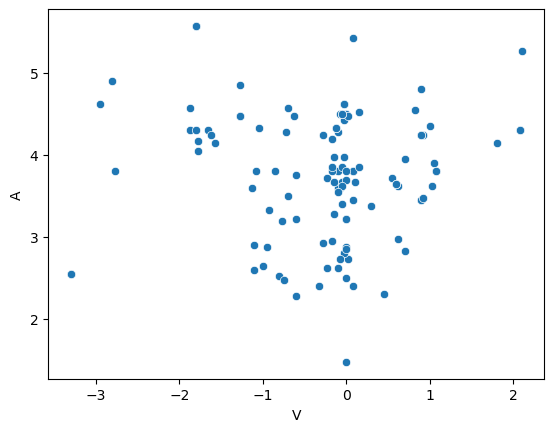

In [290]:
Dir_github = r'X:\PROJECTS\ABC@UofSC\3-Experiments\NSF_valence\github'
repo = 'ABC_valence'
# Dir_working = os.path.join(Dir_github,repo,'scripts','Behavioral','Exp_physio','pilot_Sasha')
Dir_working = os.path.join(Dir_github,'derivatives','behavioral','Exp_physio')
df_eprime = pd.read_csv(os.path.join(Dir_working,r'2.Ouputs','eprime_narrative_pilot.csv'),engine='python')

df = df_eprime.iloc[:,45:45+36].copy()
df.columns = df_eprime.columns[53:]
df['segID'] = df['path[SubTrial]'].str.rsplit("\\",1,expand=True)[1].str.split('_',expand=True)[2].str.replace('.wav','').astype(float)
df = df.loc[df['Running[SubTrial]']=='ListListenRateB']
df.loc[df['DXcoord']==0,'DXcoord'] = np.nan
df.loc[df['DYcoord']==0,'DYcoord'] = np.nan

df['V'] = rescale(df['DXcoord'],512-180,512+180,0,9).values
df['DYcoord'] *= -1
df['A'] = rescale(df['DYcoord'],-384-180,-384+180,0,9)



for label in ['V','A']:    
    df.loc[df[label]<0,label] = 0
    df.loc[df[label]>9,label] = 9


data_eprime = pd.DataFrame()
data_eprime[['story','segID','V','A']] = df[['story','segID','V','A']]
data_eprime['V'] = data_eprime['V']-4.5
sns.scatterplot(data=data_eprime,x='V',y='A')

In [ ]:
Dir_gpt = os.path.join(Dir_github,'derivatives','behavioral','ratings','gpt')
model = 'gpt-4o-2024-08-06'
dfs_rating_gpt = pd.read_csv(os.path.join(Dir_gpt,model,f'rating_gpt_{model}.csv'))
df_rating_gpt = dfs_rating_gpt.loc[dfs_rating_gpt['story']=='HowCouldYou']
data_gpt = df_rating_gpt.groupby(['idx']).mean()

Text(0, 2, 'r=0.034')

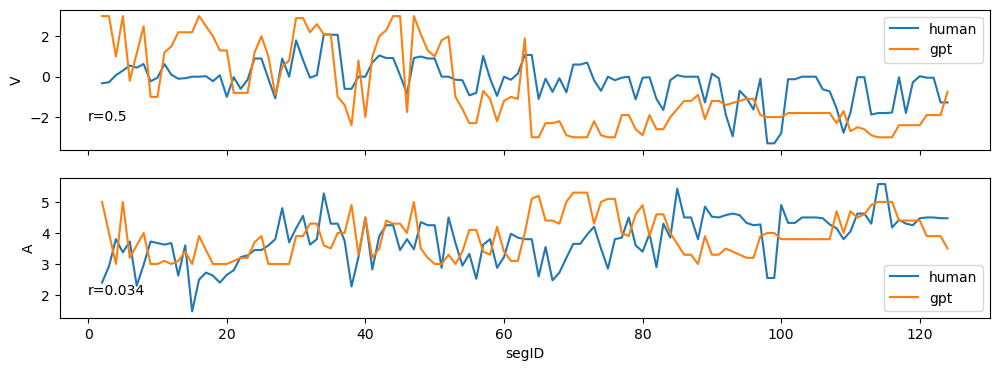

In [319]:
data_behav = pd.merge(left=data_eprime,left_on='segID',right=data_gpt[['V','A']],right_on='idx')
data_behav.columns = ['story','segID','V','A','V_gpt','A_gpt']
fig,axes = plt.subplots(ncols=1,nrows=2,figsize=(12,4),sharex=True)

ax=axes[0]
sns.lineplot(data_behav,x='segID',y='V',label='human',ax=ax)
sns.lineplot(data_behav,x='segID',y='V_gpt',label='gpt',ax=ax)
r = data_behav[['V','V_gpt']].corr().loc['V','V_gpt']
ax.text(x=0,y=-2.2,s=f"r={r.round(3)}")


ax=axes[1]
sns.lineplot(data_behav,x='segID',y='A',label='human',ax=ax)
sns.lineplot(data_behav,x='segID',y='A_gpt',label='gpt',ax=ax)
r = data_behav[['A','A_gpt']].corr().loc['A','A_gpt']
ax.text(x=0,y=2,s=f"r={r.round(3)}")

In [320]:
file = os.path.join(Dir_working,'2.Ouputs','pilot_narrative_preprocess.acq')
data = bioread.read_file(file)

In [321]:
import sys
libpath = r'Z:\study\github\bioanalysis'
sys.path.append(libpath)
import gbatch_bioanalysis  as bioana

In [322]:
design = dict()
design['channels'] = {'EDA':3,#'EDA_tonic':1,'EDA_phasic':20,
                      'EMGc':9,'EMGz':10,
                      'BPM':5,
                      'SKT':8,
                      }
design['sample_rate'] = data.samples_per_second
design['events'] = pd.DataFrame({'idx':range(4),
                                 'event':['stim_onset','stim_offset','rating_onset','trial_offset'],
                                 'label':['111','077','099','179']})

physio,events = bioana.read_data(data,design)
design['timing']= bioana.extract_trials(events,design)


In [323]:

df_timing = pd.DataFrame({'onset':design['timing']['stim_onset'],
                          'offset':design['timing']['stim_offset']})
df_timing

,onset,offset
0,415.491,415.516
1,420.373,420.400
2,424.889,425.216
3,429.907,430.283
4,434.606,436.083
...,...,...
119,1144.802,1145.813
120,1150.870,1151.379
121,1154.802,1156.629
122,1166.069,1166.096


In [324]:
df_data = bioana.extract_physiodata(physio,df_timing,design,method='mean')
df_data

,EDA,EMGc,EMGz,BPM,SKT
0,0.145649,0.000566,0.000902,80.753701,32.390701
1,0.091297,0.000539,0.001346,89.686099,32.390765
2,0.086620,0.000518,0.001147,85.592011,32.391054
3,0.236735,0.000723,0.001543,90.050512,32.391510
4,0.157603,0.000466,0.001315,86.490560,32.391917
...,...,...,...,...,...
119,0.747528,0.000760,0.000787,85.766060,32.391149
120,0.302477,0.000736,0.000646,87.533007,32.391131
121,0.473689,0.000634,0.000761,89.080172,32.390196
122,0.063990,0.000882,0.000733,89.418778,32.389191


In [345]:
df_plot

,V,A,V_gpt,A_gpt,EMGc,EMGz,EDA,BPM,SKT
V,1.000,0.011,0.500,-0.170,-0.298,0.194,-0.021,-0.002,0.316
A,0.011,1.000,-0.218,0.034,0.173,-0.276,0.287,0.215,-0.322
V_gpt,0.500,-0.218,1.000,-0.416,-0.303,0.463,-0.104,0.077,0.510
A_gpt,-0.170,0.034,-0.416,1.000,0.000,-0.106,0.036,0.044,-0.374
EMGc,-0.298,0.173,-0.303,0.000,1.000,-0.122,0.085,0.038,-0.148
EMGz,0.194,-0.276,0.463,-0.106,-0.122,1.000,0.000,0.112,0.148
EDA,-0.021,0.287,-0.104,0.036,0.085,0.000,1.000,-0.087,-0.175
BPM,-0.002,0.215,0.077,0.044,0.038,0.112,-0.087,1.000,0.071
SKT,0.316,-0.322,0.510,-0.374,-0.148,0.148,-0.175,0.071,1.000


In [348]:
from scipy.stats import pearsonr

def get_correlation(df_plot):
        

    df_p = pd.DataFrame(np.ones(df_plot.shape), columns=df_plot.columns, index=df_plot.columns)

    for i in range(len(df_plot.columns)):
        for j in range(i+1, len(df_plot.columns)):  # Avoid redundant calculations
            r, p = pearsonr(df_plot.iloc[:, i], df_plot.iloc[:, j])
            df_p.iloc[i, j] = p
            df_p.iloc[j, i] = p  # Mirror the matrix
    return(df_p)


In [352]:
df_p

,V,A,V_gpt,A_gpt,EMGc,EMGz,EDA,BPM,SKT
V,1.000000,0.338683,0.014941,0.137928,0.029571,0.291687,0.415787,0.640780,0.082483
A,0.338683,1.000000,0.072273,0.529807,0.314191,0.042252,0.196273,0.630364,0.043867
V_gpt,0.014941,0.072273,1.000000,0.019910,0.047598,0.036624,0.243617,0.879999,0.007427
A_gpt,0.137928,0.529807,0.019910,1.000000,0.614001,0.284488,0.687248,0.972873,0.028826
EMGc,0.029571,0.314191,0.047598,0.614001,1.000000,0.192943,0.594905,0.979165,0.182491
EMGz,0.291687,0.042252,0.036624,0.284488,0.192943,1.000000,0.413113,0.939707,0.242978
EDA,0.415787,0.196273,0.243617,0.687248,0.594905,0.413113,1.000000,0.405681,0.157167
BPM,0.640780,0.630364,0.879999,0.972873,0.979165,0.939707,0.405681,1.000000,0.918070
SKT,0.082483,0.043867,0.007427,0.028826,0.182491,0.242978,0.157167,0.918070,1.000000


<Axes: >

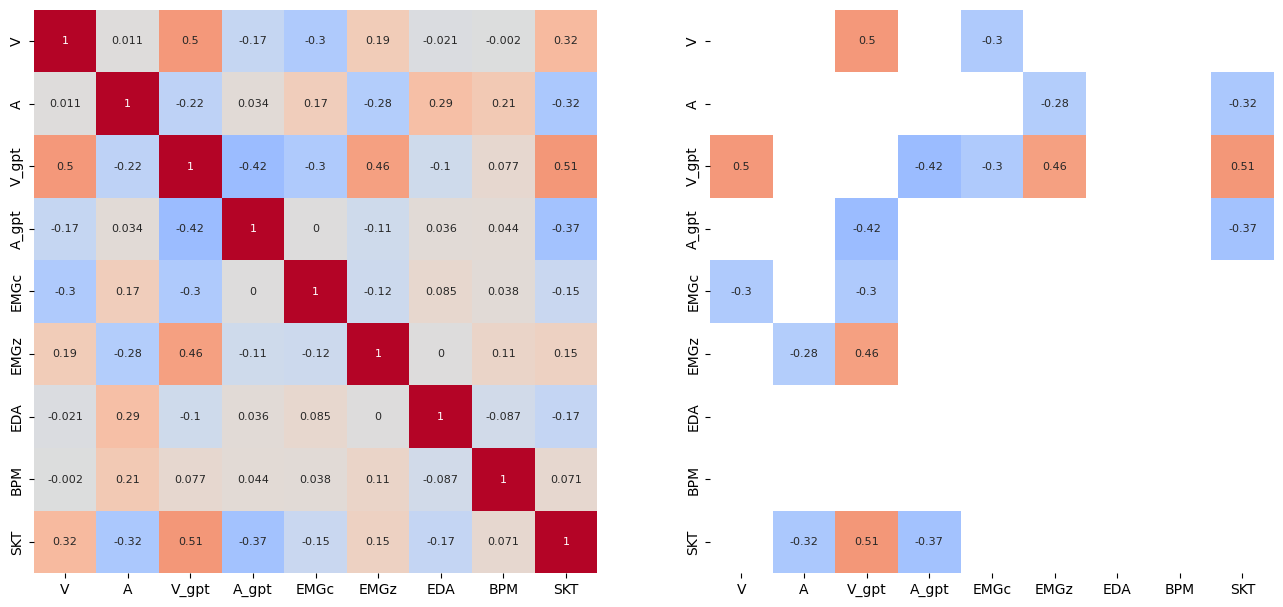

In [372]:
data_combine = pd.concat([data_behav,df_data],axis=1)[['V','A','V_gpt','A_gpt','EMGc','EMGz','EDA','BPM','SKT']]
df_plot = data_combine.corr().round(3)
df_p = get_correlation(df_plot)
fig,axes = plt.subplots(ncols=2,nrows=1,figsize=(16,8))
ax=axes[0]
sns.heatmap(df_plot,square=True,annot=True,annot_kws={"fontsize":8},
            cmap='coolwarm',
            cbar=False,
            # mask=df_p>.05,
            cbar_kws={'shrink':0.6},
            vmin=-1,vmax=1,
            ax=ax,
            # linewidths=0.1,linecolor='black'
            )

ax=axes[1]
sns.heatmap(df_plot,square=True,annot=True,annot_kws={"fontsize":8},
            cmap='coolwarm',
            mask=df_p>.05,
            cbar=False,
            cbar_kws={'shrink':0.6},
            vmin=-1,vmax=1,
            ax=ax,
            # linewidths=0.1,linecolor='black'
            )


In [141]:
sample_rate = 1000
physio = pd.DataFrame({'EDA_AUC': data.channels[3].data, 'EDA_tonic': data.channels[1].data, 
                        'BPM': data.channels[5].data, 'EMGA':data.channels[9].data, 
                        'EMGB': data.channels[10].data, 'SKT':data.channels[8].data, 
                        'label':None,'wfon':None,'scr':None,'wfof':None
                        })
physio.reset_index(inplace=True)
physio = physio.rename(columns = {'index':'id'})
physio['time']=physio['id']/sample_rate

#### Read event
for m in data.event_markers:
    if m.type_code == 'stim':
        physio.loc[m.sample_index,'label'] = m.text
    elif m.type_code == 'wfon':
        physio.loc[m.sample_index,'wfon'] = 1
    elif m.type_code == 'scr ':
        physio.loc[m.sample_index,'scr'] = 1
    elif m.type_code == 'wfof':
        physio.loc[m.sample_index,'wfof'] = 1
print(f'----> Read Data: Done.')

----> Read Data: Done.


In [159]:
Ntrials = 124
subID = '1002'
# Dir_output = os.path.join(Dir_github,'dataset','events')
# os.makedirs(Dir_output, exist_ok=True)
# path_output = os.path.join(Dir_output,f'{subID}_events.csv')

mapping_events = {'111':'stim_onset','077':'stim_offset',
            '099':'rating_onset','179':'trial_offset'}

List_channelNames = ['CameraTrigger', 'EDA_tonic', 'EMGA_raw', 'EDA_AUC', 'ECG',
        'BPM', 'EMGA_raw', 'EMGB_duplicate','SKT','EMGA_AUC',
        'EMGB_AUC','EMGB_raw']

#### read physio data
print(f'====> {subID}')
data = bioread.read_file(file)
sample_rate = data.samples_per_second

# if os.path.exists(path_output):
#     if overwrite == 0:
#         print(f'----> Data has already been extracted.')
#         physio = []
#         events = []
#         return physio,events,sample_rate

if len(data.channels) != 22:
    print('----> Error: The number of channels is not correct.')
    physio = []
    events = []
    # return physio,events,sample_rate

physio = pd.DataFrame({'EDA_AUC': data.channels[3].data, 'EDA_tonic': data.channels[1].data, 
                        'BPM': data.channels[5].data, 'EMGA':data.channels[9].data, 
                        'EMGB': data.channels[10].data, 'SKT':data.channels[8].data, 
                        'label':None,'wfon':None,'scr':None,'wfof':None
                        })
physio.reset_index(inplace=True)
physio = physio.rename(columns = {'index':'id'})
physio['time']=physio['id']/sample_rate

#### Read event
for m in data.event_markers:
    if m.type_code == 'stim':
        physio.loc[m.sample_index,'label'] = m.text
    elif m.type_code == 'wfon':
        physio.loc[m.sample_index,'wfon'] = 1
    elif m.type_code == 'scr ':
        physio.loc[m.sample_index,'scr'] = 1
    elif m.type_code == 'wfof':
        physio.loc[m.sample_index,'wfof'] = 1
print(f'----> Read Data: Done.')

# if subID=='sub-20393':
#     physio.loc[physio.time<1956,'label'] = None
        
#### extract timings
physio['event'] = physio['label'].map(mapping_events)

events = pd.DataFrame({'trialID':list(range(1,Ntrials+1)),
                        # 'modality':physio.loc[~physio.modality.isna(),'modality'].values,
                        # 'avertype':physio.loc[~physio.avertype.isna(),'avertype'].values,
                        })
for event in ['stim_onset', 'stim_offset', 'rating_onset','trial_offset']:
    events[f'{event}'] = physio.loc[physio.event==event,'time'].values


====> 1002
----> Read Data: Done.


In [193]:
dfs_physio_tw = []
for i,row in events.iterrows():
    onset = 0
    offset = row['stim_offset'] - row['stim_onset']
    idx1 = physio.loc[physio.time==round(row['stim_onset']+onset,3),'id'].values[0] # time window onset
    idx2 = physio.loc[physio.time==round(row['stim_onset']+onset+offset,3),'id'].values[0] # time window offset
    idx0 = physio.loc[physio.time==round(row['stim_onset']-1,3),'id'].values[0] # 1s prior to the stimulus presentation onset
    
    df_physio_tw = physio.loc[idx0:idx2-1,['EDA_AUC','BPM','EMGA','EMGB','SKT','wfon','scr','wfof','time']].reset_index(drop=True)
    df_physio_tw['time'] = round(df_physio_tw['time']-df_physio_tw.loc[0,'time']-1,3)

    df_physio_tw[['trialID']] = row[['trialID']]
    df_physio_tw['onset'] = onset
    df_physio_tw['offset'] = offset
    dfs_physio_tw.append(df_physio_tw)
dfs_physio_tw = pd.concat(dfs_physio_tw,ignore_index=True)
dfs_physio_tw['subID'] = subID


In [190]:
df_tw = dfs_physio_tw.copy()
df_bl = df_tw.loc[df_tw['time']<0].reset_index(drop=True) #-1 to 0

# Calculate the feature for every trial
df_bl_bytrial = []
for trialID in df_tw['trialID'].unique():
    df_tmp_bl = df_bl.loc[df_bl['trialID']==trialID].reset_index(drop=True)
    for df,dfs in zip([df_tmp_bl],[df_bl_bytrial]):
        dfs.append(pd.DataFrame({'EDA_AUC':trapz(df['EDA_AUC'], df['time']),
                                    'BPM':df['BPM'].mean(),
                                    'EMGA_AUC':trapz(df['EMGA'], df['time']),
                                    'EMGB_AUC':trapz(df['EMGB'], df['time']),
                                #  'EMGA_mean':df['EMGA'].mean(),
                                #  'EMGB_mean':df['EMGB'].mean(),
                                #  'EMGA_diff':df['EMGA'].max()-df['EMGA'].min(),
                                #  'EMGB_diff':df['EMGB'].max()-df['EMGB'].min(),
                                    'SKT':df['SKT'].mean(),
                                    'trialID':df.loc[0,'trialID']
                                },index=[0]))
df_bl_bytrial = pd.concat(df_bl_bytrial,ignore_index=True)

In [203]:
df_tw = dfs_physio_tw.copy()
onset = 0
# Extract the data from the timewindow specified
# Calculate the feature for every trial
df_tw_bytrial = []
for trialID in df_tw['trialID'].unique():
    df_tmp = df_tw.loc[df_tw['trialID']==trialID].reset_index(drop=True)
    offset = df_tmp.loc[0,'offset']
    df_tmp = df_tmp.loc[(df_tmp['time']>=onset)&(df_tmp['time']<offset)].reset_index(drop=True)
    for df,dfs in zip([df_tmp],[df_tw_bytrial]):
        dfs.append(pd.DataFrame({'EDA_AUC':trapz(df['EDA_AUC'], df['time']),
                                    'BPM':df['BPM'].mean(),
                                    'EMGA_AUC':trapz(df['EMGA'], df['time']),
                                    'EMGB_AUC':trapz(df['EMGB'], df['time']),
                                #  'EMGA_mean':df['EMGA'].mean(),
                                #  'EMGB_mean':df['EMGB'].mean(),
                                #  'EMGA_diff':df['EMGA'].max()-df['EMGA'].min(),
                                #  'EMGB_diff':df['EMGB'].max()-df['EMGB'].min(),
                                    'SKT':df['SKT'].mean(),
                                    # 'avertype':df.loc[0,'avertype'],
                                    # 'modality':df.loc[0,'modality'],
                                    'trialID':df.loc[0,'trialID']
                                },index=[0]))
df_tw_bytrial = pd.concat(df_tw_bytrial,ignore_index=True)
df_tw_bytrial['subID'] = subID

with warnings.catch_warnings():
    warnings.simplefilter("ignore", category=RuntimeWarning)
    for i,channel in enumerate(['EDA_AUC','EMGA_AUC','EMGB_AUC','BPM','SKT']):
        df = pd.DataFrame({'x':df_tw_bytrial[channel].values,
                            'lg(x)':np.log10(df_tw_bytrial[channel].values),
                            'lg(bl)':np.log10(df_bl_bytrial[channel].values),
                            'x-bl':df_tw_bytrial[channel].values - df_bl_bytrial[channel].values,
                            'lg(x-bl+10)':np.log10(df_tw_bytrial[channel].values-df_bl_bytrial[channel].values+10),
                            'lg(x)-lg(bl)':np.log10(df_tw_bytrial[channel].values) - np.log10(df_bl_bytrial[channel].values)
                            })
        for j,var in enumerate(['x','lg(x)','lg(bl)','x-bl','lg(x-bl+10)','lg(x)-lg(bl)']):

            df[f'{var}_z'] = stats.zscore(df[var].values)

        for var in df.columns:
            df_tw_bytrial[f'{channel}_{var}'] = df[var].values

# df_tw_bytrial['onset'] = onset
# df_tw_bytrial['offset'] = offset
List_vars = ['subID','trialID']
df_tw_bytrial = df_tw_bytrial[List_vars + [x for x in df_tw_bytrial.columns if x not in List_vars]]
df_tw_bytrial

,subID,trialID,EDA_AUC,BPM,EMGA_AUC,EMGB_AUC,SKT,EDA_AUC_x,EDA_AUC_lg(x),EDA_AUC_lg(bl),...,SKT_lg(bl),SKT_x-bl,SKT_lg(x-bl+10),SKT_lg(x)-lg(bl),SKT_x_z,SKT_lg(x)_z,SKT_lg(bl)_z,SKT_x-bl_z,SKT_lg(x-bl+10)_z,SKT_lg(x)-lg(bl)_z
0,1002,1.0,0.003495,80.753701,0.000014,0.000022,32.390700,0.003495,-2.456564,-1.077532,...,1.510419,0.000068,1.000003,9.161087e-07,-1.596368,-1.596404,-1.634965,0.537147,0.537148,0.537201
1,1002,2.0,0.002369,89.686099,0.000014,0.000035,32.390766,0.002369,-2.625477,-0.796467,...,1.510421,-0.000020,0.999999,-2.634403e-07,-1.560463,-1.560496,-1.551427,-0.122776,-0.122769,-0.122791
2,1002,3.0,0.028250,85.592011,0.000169,0.000374,32.391053,0.028250,-1.548977,-0.828257,...,1.510425,0.000039,1.000002,5.258801e-07,-1.404743,-1.404764,-1.427591,0.318829,0.318833,0.318857
3,1002,4.0,0.088798,90.059742,0.000271,0.000578,32.391510,0.088798,-1.051597,-0.762045,...,1.510430,0.000054,1.000002,7.183202e-07,-1.157547,-1.157551,-1.188182,0.426501,0.426503,0.426533
4,1002,5.0,0.232545,86.494591,0.000688,0.001940,32.391917,0.232545,-0.633493,-0.403289,...,1.510434,0.000183,1.000008,2.459953e-06,-0.936927,-0.936919,-1.037911,1.400932,1.400916,1.401026
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
119,1002,120.0,0.755221,85.762840,0.000767,0.000795,32.391149,0.755221,-0.121926,-0.403808,...,1.510425,0.000116,1.000005,1.556930e-06,-1.352914,-1.352931,-1.417401,0.895680,0.895675,0.895759
120,1002,121.0,0.153669,87.521367,0.000374,0.000328,32.391131,0.153669,-0.813414,-0.486408,...,1.510427,-0.000100,0.999996,-1.343020e-06,-1.362527,-1.362545,-1.309906,-0.726781,-0.726773,-0.726847
121,1002,122.0,0.865458,89.084848,0.001157,0.001390,32.390196,0.865458,-0.062754,-0.346923,...,1.510417,-0.000269,0.999988,-3.612499e-06,-1.869037,-1.869099,-1.724745,-1.996455,-1.996461,-1.996686
122,1002,123.0,0.001664,89.418778,0.000023,0.000019,32.389202,0.001664,-2.778813,-1.420179,...,1.510401,-0.000042,0.999998,-5.617636e-07,-2.407095,-2.407220,-2.385992,-0.289665,-0.289657,-0.289711


In [232]:
(1180.564 - 415.491	+10*124)/60

33.417883333333336

In [205]:
data_physio = pd.DataFrame()
data_physio[['subid','trialID','EDA','EMGc','EMGz','BPM','SKT']] =  df_tw_bytrial[['subID','trialID','EDA_AUC_lg(x)-lg(bl)_z','EMGA_AUC_lg(x)-lg(bl)_z','EMGB_AUC_lg(x)-lg(bl)_z','BPM_x-bl_z','SKT_x-bl_z']].copy()

In [213]:
data = pd.merge(left=data_physio,left_on='trialID',right=data_eprime,right_on='segID',how='left')
data

,subid,trialID,EDA,EMGc,EMGz,BPM,SKT,story,segID,V,A
0,1002,1.0,-1.645318,-2.497077,-2.586691,-0.215804,0.537147,HowCouldYou,1.0,NaN,NaN
1,1002,2.0,-2.287425,-2.375274,-2.429153,-0.162933,-0.122776,HowCouldYou,2.0,499.0,468.0
2,1002,3.0,-0.705922,-0.562791,-0.604076,0.015771,0.318829,HowCouldYou,3.0,501.0,447.0
3,1002,4.0,-0.090656,-0.135037,-0.431100,0.885869,0.426501,HowCouldYou,4.0,515.0,412.0
4,1002,5.0,-0.005967,0.418815,0.410303,-1.678430,1.400932,HowCouldYou,5.0,524.0,429.0
...,...,...,...,...,...,...,...,...,...,...,...
119,1002,120.0,0.724767,0.145917,0.239504,-1.362824,0.895680,HowCouldYou,120.0,513.0,385.0
120,1002,121.0,-0.144103,-0.231432,-0.214956,0.760492,-0.726781,HowCouldYou,121.0,510.0,384.0
121,1002,122.0,0.728030,0.732302,0.594022,-2.141625,-1.996455,HowCouldYou,122.0,510.0,384.0
122,1002,123.0,-1.616211,-2.401454,-2.349735,-0.191937,-0.289665,HowCouldYou,123.0,461.0,385.0


<Axes: xlabel='trialID', ylabel='A'>

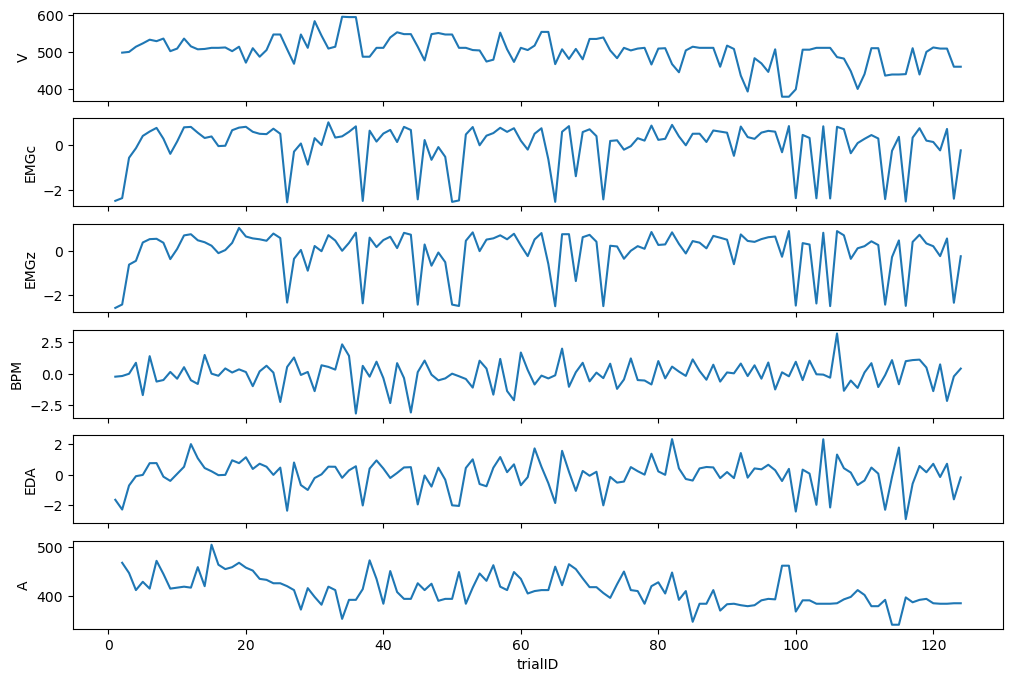

In [245]:
fig,axes = plt.subplots(ncols=1,nrows=6,figsize=(12,8),sharex=True)
sns.lineplot(data=data,x='trialID',y='V',ax=axes[0])
sns.lineplot(data=data,x='trialID',y='EMGc',ax=axes[1])
sns.lineplot(data=data,x='trialID',y='EMGz',ax=axes[2])
sns.lineplot(data=data,x='trialID',y='BPM',ax=axes[3])
sns.lineplot(data=data,x='trialID',y='EDA',ax=axes[4])
sns.lineplot(data=data,x='trialID',y='A',ax=axes[5])

In [ ]:
# subset of stimuli (remove neutral)
# correlate Listen vs. ListenRate
# EMGc and EMGz, if are calcualted from the same channel

# gpt correlate with participant

# x axis -> seconds, middle/onset of the segment, different space between points 
# r as a function of time lag

<Axes: >

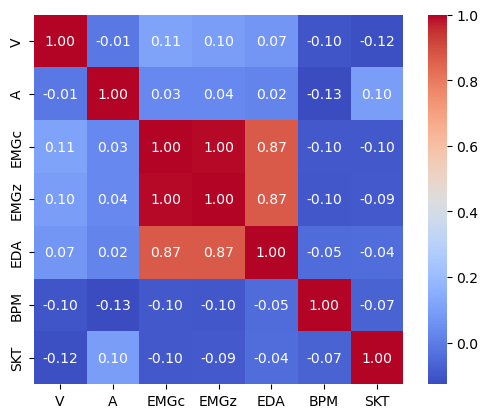

In [242]:
df_plot = data[['V','A','EMGc','EMGz','EDA','BPM','SKT']].corr()
sns.heatmap(df_plot, annot=True, fmt=".2f", cmap="coolwarm",square=True)